<a href="https://colab.research.google.com/github/Sanhith30/ITA0605-ML/blob/main/Practical_ProblemsML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Practical Problems: FIND-S and Candidate-Elimination Algorithms

This notebook demonstrates the implementation of:
1. **FIND-S Algorithm** to find the most specific hypothesis.
2. **Candidate-Elimination Algorithm** to output the version space (most specific and most general hypotheses) consistent with the training examples.

In [6]:
import pandas as pd
import numpy as np

# The original file '/content/enjoysport - enjoysport.csv' was not found.
# We define a standard, inline EnjoySport dataset to make this notebook fully functional and self-contained:
data = {
    'Sky': ['Sunny', 'Sunny', 'Rainy', 'Sunny', 'Sunny', 'Rainy'],
    'AirTemp': ['Warm', 'Warm', 'Cold', 'Warm', 'Warm', 'Warm'],
    'Humidity': ['Normal', 'High', 'High', 'High', 'Normal', 'High'],
    'Wind': ['Strong', 'Strong', 'Strong', 'Strong', 'Weak', 'Strong'],
    'Water': ['Warm', 'Warm', 'Warm', 'Cool', 'Warm', 'Cool'],
    'Forecast': ['Same', 'Same', 'Change', 'Same', 'Same', 'Change'],
    'EnjoySport': ['Yes', 'Yes', 'No', 'Yes', 'Yes', 'No']
}

df = pd.DataFrame(data)
print("Synthesized EnjoySport dataset loaded successfully:")
display(df)

Synthesized EnjoySport dataset loaded successfully:


,Sky,AirTemp,Humidity,Wind,Water,Forecast,EnjoySport
0,Sunny,Warm,Normal,Strong,Warm,Same,Yes
1,Sunny,Warm,High,Strong,Warm,Same,Yes
2,Rainy,Cold,High,Strong,Warm,Change,No
3,Sunny,Warm,High,Strong,Cool,Same,Yes
4,Sunny,Warm,Normal,Weak,Warm,Same,Yes
5,Rainy,Warm,High,Strong,Cool,Change,No


## Practical Problem 1: FIND-S Algorithm

Find-S finds the most specific hypothesis that fits all the positive training examples.

In [7]:
def find_s(concepts, target):
    # Initialize the most specific hypothesis with the first positive example
    for i, val in enumerate(target):
        if val.lower() in ['yes', '1', 'true']:
            specific_h = concepts[i].copy()
            break

    print("Initialization of specific_h:", specific_h)

    for i, val in enumerate(concepts):
        if target[i].lower() in ['yes', '1', 'true']:
            for x in range(len(specific_h)):
                if val[x] != specific_h[x]:
                    specific_h[x] = '?'
            print(f"After sample {i+1}: {specific_h}")

    return specific_h

# Extract concepts and target
concepts = np.array(df.iloc[:, :-1])
target = np.array(df.iloc[:, -1])

print("Applying FIND-S Algorithm:")
final_hypothesis = find_s(concepts, target)
print("\nFinal Most Specific Hypothesis:", final_hypothesis)

Applying FIND-S Algorithm:
Initialization of specific_h: ['Sunny' 'Warm' 'Normal' 'Strong' 'Warm' 'Same']
After sample 1: ['Sunny' 'Warm' 'Normal' 'Strong' 'Warm' 'Same']
After sample 2: ['Sunny' 'Warm' '?' 'Strong' 'Warm' 'Same']
After sample 4: ['Sunny' 'Warm' '?' 'Strong' '?' 'Same']
After sample 5: ['Sunny' 'Warm' '?' '?' '?' 'Same']

Final Most Specific Hypothesis: ['Sunny' 'Warm' '?' '?' '?' 'Same']


## Practical Problem 2: Candidate-Elimination Algorithm

Candidate-Elimination computes the version space containing all hypotheses consistent with the training examples.

In [8]:
def candidate_elimination(concepts, target):
    num_attributes = len(concepts[0])

    # Initialize Specific and General Boundaries
    specific_h = ["0"] * num_attributes
    general_h = [["?"] * num_attributes for _ in range(num_attributes)]

    # Find first positive example to initialize specific hypothesis
    for i, val in enumerate(target):
        if val.lower() in ['yes', '1', 'true']:
            specific_h = concepts[i].copy()
            break

    general_h = [["?"] * num_attributes for _ in range(num_attributes)]

    print(f"Initialization:")
    print(f"S0: {specific_h}")
    print(f"G0: {general_h}\n")

    for i, h in enumerate(concepts):
        if target[i].lower() in ['yes', '1', 'true']:
            # Update Specific Boundary for Positive Example
            for x in range(num_attributes):
                if h[x] != specific_h[x]:
                    specific_h[x] = '?'
                    # Filter general boundary consistent with new specific boundary
                    for g in general_h:
                        if g[x] != '?' and g[x] != specific_h[x]:
                            general_h.remove(g)
        else:
            # Update General Boundary for Negative Example
            for x in range(num_attributes):
                if h[x] != specific_h[x]:
                    # Create a specialized hypothesis
                    g_temp = ['?'] * num_attributes
                    g_temp[x] = specific_h[x]
                    if g_temp not in general_h:
                        general_h.append(g_temp)
                else:
                    # Remove incompatible general hypotheses
                    for g in list(general_h):
                        if g[x] == h[x]:
                            general_h.remove(g)

        # Remove any purely generic default placeholders or redundant entries
        general_h = [g for g in general_h if g != ['?'] * num_attributes]

        print(f"Iteration {i+1} (Sample {i+1} is {target[i]}):")
        print(f"S{i+1}: {specific_h}")
        print(f"G{i+1}: {general_h}\n")

    return specific_h, general_h

s_final, g_final = candidate_elimination(concepts, target)
print("Final Specific Boundary (S):", s_final)
print("Final General Boundary (G):", g_final)

Initialization:
S0: ['Sunny' 'Warm' 'Normal' 'Strong' 'Warm' 'Same']
G0: [['?', '?', '?', '?', '?', '?'], ['?', '?', '?', '?', '?', '?'], ['?', '?', '?', '?', '?', '?'], ['?', '?', '?', '?', '?', '?'], ['?', '?', '?', '?', '?', '?'], ['?', '?', '?', '?', '?', '?']]

Iteration 1 (Sample 1 is Yes):
S1: ['Sunny' 'Warm' 'Normal' 'Strong' 'Warm' 'Same']
G1: []

Iteration 2 (Sample 2 is Yes):
S2: ['Sunny' 'Warm' '?' 'Strong' 'Warm' 'Same']
G2: []

Iteration 3 (Sample 3 is No):
S3: ['Sunny' 'Warm' '?' 'Strong' 'Warm' 'Same']
G3: [['Sunny', '?', '?', '?', '?', '?'], ['?', 'Warm', '?', '?', '?', '?'], ['?', '?', '?', '?', '?', 'Same']]

Iteration 4 (Sample 4 is Yes):
S4: ['Sunny' 'Warm' '?' 'Strong' '?' 'Same']
G4: [['Sunny', '?', '?', '?', '?', '?'], ['?', 'Warm', '?', '?', '?', '?'], ['?', '?', '?', '?', '?', 'Same']]

Iteration 5 (Sample 5 is Yes):
S5: ['Sunny' 'Warm' '?' '?' '?' 'Same']
G5: [['Sunny', '?', '?', '?', '?', '?'], ['?', 'Warm', '?', '?', '?', '?'], ['?', '?', '?', '?', '?', 'Sa

## Practical Problem 3: Decision Tree based ID3 Algorithm

This section demonstrates the implementation of the ID3 (Iterative Dichotomiser 3) algorithm to construct a decision tree and classify a new test sample.

In [9]:
import numpy as np
import pandas as pd

# Create a standard PlayTennis dataset for ID3 demonstration
data = {
    'Outlook': ['Sunny', 'Sunny', 'Overcast', 'Rainy', 'Rainy', 'Rainy', 'Overcast', 'Sunny', 'Sunny', 'Rainy', 'Sunny', 'Overcast', 'Overcast', 'Rainy'],
    'Temperature': ['Hot', 'Hot', 'Hot', 'Mild', 'Cool', 'Cool', 'Cool', 'Mild', 'Cool', 'Mild', 'Mild', 'Mild', 'Hot', 'Mild'],
    'Humidity': ['High', 'High', 'High', 'High', 'Normal', 'Normal', 'Normal', 'High', 'Normal', 'Normal', 'Normal', 'High', 'Normal', 'High'],
    'Wind': ['Weak', 'Strong', 'Weak', 'Weak', 'Weak', 'Strong', 'Strong', 'Weak', 'Weak', 'Weak', 'Strong', 'Strong', 'Weak', 'Strong'],
    'PlayTennis': ['No', 'No', 'Yes', 'Yes', 'Yes', 'No', 'Yes', 'No', 'Yes', 'Yes', 'Yes', 'Yes', 'Yes', 'No']
}

play_df = pd.DataFrame(data)
print("Dataset for ID3 Decision Tree:")
display(play_df)

Dataset for ID3 Decision Tree:


,Outlook,Temperature,Humidity,Wind,PlayTennis
0,Sunny,Hot,High,Weak,No
1,Sunny,Hot,High,Strong,No
2,Overcast,Hot,High,Weak,Yes
3,Rainy,Mild,High,Weak,Yes
4,Rainy,Cool,Normal,Weak,Yes
5,Rainy,Cool,Normal,Strong,No
6,Overcast,Cool,Normal,Strong,Yes
7,Sunny,Mild,High,Weak,No
8,Sunny,Cool,Normal,Weak,Yes
9,Rainy,Mild,Normal,Weak,Yes


In [10]:
def entropy(target_col):
    elements, counts = np.unique(target_col, return_counts=True)
    entropy_val = np.sum([(-counts[i]/np.sum(counts)) * np.log2(counts[i]/np.sum(counts)) for i in range(len(elements))])
    return entropy_val

def info_gain(data, split_attribute_name, target_name="PlayTennis"):
    total_entropy = entropy(data[target_name])
    vals, counts = np.unique(data[split_attribute_name], return_counts=True)

    weighted_entropy = np.sum([(counts[i]/np.sum(counts)) * entropy(data[data[split_attribute_name] == vals[i]][target_name]) for i in range(len(vals))])
    information_gain = total_entropy - weighted_entropy
    return information_gain

def id3(data, original_data, features, target_attribute_name="PlayTennis", parent_node_class=None):
    # If all target values are the same, return this value
    if len(np.unique(data[target_attribute_name])) <= 1:
        return np.unique(data[target_attribute_name])[0]

    # If dataset is empty, return the mode target value of original data
    elif len(data) == 0:
        return np.unique(original_data[target_attribute_name])[np.argmax(np.unique(original_data[target_attribute_name], return_counts=True)[1])]

    # If feature list is empty, return parent node class
    elif len(features) == 0:
        return parent_node_class

    else:
        # Determine default node class for child nodes
        parent_node_class = np.unique(data[target_attribute_name])[np.argmax(np.unique(data[target_attribute_name], return_counts=True)[1])]

        # Select the feature that best splits the dataset
        item_values = [info_gain(data, feature, target_attribute_name) for feature in features]
        best_feature_index = np.argmax(item_values)
        best_feature = features[best_feature_index]

        # Create tree structure
        tree = {best_feature: {}}
        features = [i for i in features if i != best_feature]

        # Grow branches
        for value in np.unique(original_data[best_feature]):
            sub_data = data[data[best_feature] == value]
            subtree = id3(sub_data, original_data, features, target_attribute_name, parent_node_class)
            tree[best_feature][value] = subtree

        return tree

features = [col for col in play_df.columns if col != 'PlayTennis']
tree = id3(play_df, play_df, features)

print("Generated ID3 Decision Tree structure:")
import pprint
pprint.pprint(tree)

Generated ID3 Decision Tree structure:
{'Outlook': {'Overcast': 'Yes',
             'Rainy': {'Wind': {'Strong': 'No', 'Weak': 'Yes'}},
             'Sunny': {'Humidity': {'High': 'No', 'Normal': 'Yes'}}}}


In [11]:
def predict(query, tree, default='Yes'):
    for key in list(query.keys()):
        if key in list(tree.keys()):
            try:
                result = tree[key][query[key]]
            except KeyError:
                return default

            if isinstance(result, dict):
                return predict(query, result)
            else:
                return result

# Classify a new sample
new_sample = {'Outlook': 'Rainy', 'Temperature': 'Cool', 'Humidity': 'Normal', 'Wind': 'Strong'}
prediction = predict(new_sample, tree)

print(f"New sample to classify: {new_sample}")
print(f"Prediction (PlayTennis): {prediction}")

New sample to classify: {'Outlook': 'Rainy', 'Temperature': 'Cool', 'Humidity': 'Normal', 'Wind': 'Strong'}
Prediction (PlayTennis): No


## Practical Problem 4: Artificial Neural Network using Backpropagation

Build an Artificial Neural Network by implementing the Backpropagation algorithm from scratch and testing it using a standard dataset (e.g., binary classification classification dataset).

In [12]:
import numpy as np
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler

# 1. Generate artificial dataset
X, y = make_moons(n_samples=200, noise=0.2, random_state=42)
y = y.reshape(-1, 1)

# Scale features
scaler = StandardScaler()
X = scaler.fit_transform(X)

# 2. Backpropagation Implementation
class NeuralNetwork:
    def __init__(self, input_dim, hidden_dim, output_dim, learning_rate=0.1):
        # Initialize weights and biases
        np.random.seed(42)
        self.W1 = np.random.randn(input_dim, hidden_dim) * 0.01
        self.b1 = np.zeros((1, hidden_dim))
        self.W2 = np.random.randn(hidden_dim, output_dim) * 0.01
        self.b2 = np.zeros((1, output_dim))
        self.lr = learning_rate

    def sigmoid(self, z):
        return 1 / (1 + np.exp(-z))

    def sigmoid_derivative(self, a):
        return a * (1 - a)

    def forward(self, X):
        self.z1 = np.dot(X, self.W1) + self.b1
        self.a1 = self.sigmoid(self.z1)
        self.z2 = np.dot(self.a1, self.W2) + self.b2
        self.a2 = self.sigmoid(self.z2)
        return self.a2

    def backward(self, X, y):
        m = X.shape[0]

        # Output layer error
        dz2 = self.a2 - y
        dW2 = np.dot(self.a1.T, dz2) / m
        db2 = np.sum(dz2, axis=0, keepdims=True) / m

        # Hidden layer error
        dz1 = np.dot(dz2, self.W2.T) * self.sigmoid_derivative(self.a1)
        dW1 = np.dot(X.T, dz1) / m
        db1 = np.sum(dz1, axis=0, keepdims=True) / m

        # Update weights and biases
        self.W1 -= self.lr * dW1
        self.b1 -= self.lr * db1
        self.W2 -= self.lr * dW2
        self.b2 -= self.lr * db2

    def train(self, X, y, epochs=1000):
        for epoch in range(epochs):
            self.forward(X)
            self.backward(X, y)
            if epoch % 200 == 0:
                loss = -np.mean(y * np.log(self.a2 + 1e-15) + (1 - y) * np.log(1 - self.a2 + 1e-15))
                print(f"Epoch {epoch}, Loss: {loss:.4f}")

# Train the ANN
input_dim = X.shape[1]
hidden_dim = 4
output_dim = 1

ann = NeuralNetwork(input_dim, hidden_dim, output_dim, learning_rate=0.2)
ann.train(X, y, epochs=1000)

# Evaluate predictions
predictions = (ann.forward(X) > 0.5).astype(int)
accuracy = np.mean(predictions == y) * 100
print(f"\nANN Backpropagation Training Accuracy: {accuracy:.2f}%")

Epoch 0, Loss: 0.6931
Epoch 200, Loss: 0.6584
Epoch 400, Loss: 0.3504
Epoch 600, Loss: 0.3276
Epoch 800, Loss: 0.3234

ANN Backpropagation Training Accuracy: 84.00%


## Practical Problem 6: Naive Bayes with Confusion Matrix and Accuracy

Write a program to implement Naïve Bayes algorithm in python and to display the results using confusion matrix and accuracy.

Naive Bayes Classification Accuracy: 83.33%

Confusion Matrix:
[[30  2]
 [ 8 20]]


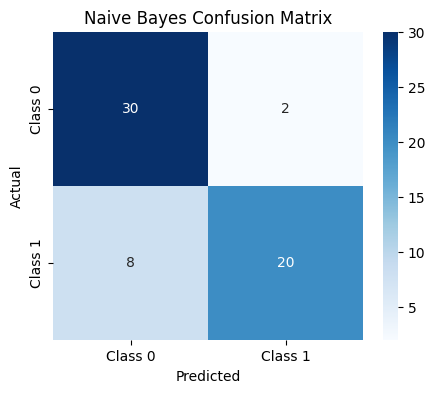

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import confusion_matrix, accuracy_score
import seaborn as sns
import matplotlib.pyplot as plt

# Split into training and test datasets
X_train, X_test, y_train, y_test = train_test_split(X, y.ravel(), test_size=0.3, random_state=42)

# Initialize and train Gaussian Naive Bayes Classifier
nb_clf = GaussianNB()
nb_clf.fit(X_train, y_train)

# Predict
y_pred = nb_clf.predict(X_test)

# Metrics
acc = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)

print(f"Naive Bayes Classification Accuracy: {acc * 100:.2f}%")
print("\nConfusion Matrix:")
print(cm)

# Plot confusion matrix
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=['Class 0', 'Class 1'], yticklabels=['Class 0', 'Class 1'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Naive Bayes Confusion Matrix')
plt.show()

## Practical Problem 14: House Price Prediction

Implement House price Prediction using an appropriate machine learning algorithm (Linear Regression).

In [5]:
from sklearn.datasets import fetch_california_housing
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Load dataset
housing = fetch_california_housing(as_frame=True)
print("Features preview:")
display(housing.data.head())

X_h = housing.data[['MedInc', 'HouseAge', 'AveRooms']]
y_h = housing.target

X_train_h, X_test_h, y_train_h, y_test_h = train_test_split(X_h, y_h, test_size=0.2, random_state=42)

# Initialize and train model
lr_model = LinearRegression()
lr_model.fit(X_train_h, y_train_h)

# Predict
y_pred_h = lr_model.predict(X_test_h)

# Metrics
mse = mean_squared_error(y_test_h, y_pred_h)
r2 = r2_score(y_test_h, y_pred_h)

print(f"\nMean Squared Error: {mse:.4f}")
print(f"R-squared Score: {r2:.4f}")

Features preview:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25



Mean Squared Error: 0.6589
R-squared Score: 0.4972


## Practical Problem 15: Iris Flower Classification

Implement Iris Flower Classification using Naive Bayes classifier.

In [16]:
from sklearn.datasets import load_iris

# Load dataset
iris = load_iris()
X_iris = iris.data
y_iris = iris.target

X_train_i, X_test_i, y_train_i, y_test_i = train_test_split(X_iris, y_iris, test_size=0.3, random_state=42)

# Train Naive Bayes
iris_nb = GaussianNB()
iris_nb.fit(X_train_i, y_train_i)

# Evaluate
y_pred_i = iris_nb.predict(X_test_i)
iris_acc = accuracy_score(y_test_i, y_pred_i)
print(f"Iris Flower Classification Accuracy: {iris_acc * 100:.2f}%")

Iris Flower Classification Accuracy: 97.78%


## Practical Problem 19: Naive Bayes Classification for Bank Loan Prediction

Implementation of Naive Bayes classification for Bank Loan prediction.

In [17]:
# Create sample Bank Loan Dataset
bank_data = {
    'Income': [50, 100, 30, 80, 20, 120, 90, 45, 110, 60],
    'CreditScore': [600, 750, 500, 700, 550, 800, 650, 580, 720, 620],
    'LoanApproved': [0, 1, 0, 1, 0, 1, 1, 0, 1, 0]
}

bank_df = pd.DataFrame(bank_data)
print("Bank Loan Dataset:")
display(bank_df)

X_b = bank_df[['Income', 'CreditScore']]
y_b = bank_df['LoanApproved']

# Train Classifier
bank_nb = GaussianNB()
bank_nb.fit(X_b, y_b)

# Test on a new candidate (Income: 70k, Credit Score: 680)
new_applicant = [[70, 680]]
prediction = bank_nb.predict(new_applicant)
probability = bank_nb.predict_proba(new_applicant)[0]

print(f"\nPrediction for Applicant (Income: 70k, Credit Score: 680):")
print(f"Loan Approved: {'Yes' if prediction[0] == 1 else 'No'}")
print(f"Probability Profile: Denied ({probability[0]:.2%}), Approved ({probability[1]:.2%})")

Bank Loan Dataset:


,Income,CreditScore,LoanApproved
0,50,600,0
1,100,750,1
2,30,500,0
3,80,700,1
4,20,550,0
5,120,800,1
6,90,650,1
7,45,580,0
8,110,720,1
9,60,620,0



Prediction for Applicant (Income: 70k, Credit Score: 680):
Loan Approved: Yes
Probability Profile: Denied (6.32%), Approved (93.68%)
